# Reinforcement Learning

Every other learning page in this section shows the model the right answer.
Supervised learning has labels; [[cross-validation]] measures how well they were
fitted. Reinforcement learning has none of that, and three things change:

| | supervised | reinforcement |
|---|---|---|
| signal | the correct output | a scalar reward, possibly much later |
| data | fixed, given | **generated by your own behaviour** |
| objective | match the label | maximise long-run return |

The second row is the one that makes RL genuinely different. Your policy decides
which states you visit, so it decides which data you get to learn from. Change
the policy and the data distribution changes underneath you — there is no fixed
training set to cross-validate against.

This page builds the machinery from the ground up on a gridworld small enough to
print, and ends at the policy-gradient estimator that
[[rlhf-grpo-constitutional-ai]] uses. Every value is computed by hand and checked
against an exact solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

banner("A GRIDWORLD SMALL ENOUGH TO PRINT")

# 3 rows x 4 cols. (0,3) is a +1 terminal, (1,3) is a -1 terminal,
# (1,1) is a wall. Every other step costs -0.04.
ROWS, COLS = 3, 4
WALL, GOAL, PIT = (1, 1), (0, 3), (1, 3)
STEP_R, GAMMA = -0.04, 0.9
ACTIONS = ['up', 'down', 'left', 'right']
DELTA = {'up': (-1, 0), 'down': (1, 0), 'left': (0, -1), 'right': (0, 1)}
SLIP = 0.1                      # probability of veering to each side

states = [(r, c) for r in range(ROWS) for c in range(COLS)
          if (r, c) != WALL]
terminals = {GOAL: +1.0, PIT: -1.0}

def show_grid(vals, title, fmt="{:+7.3f}"):
    print(f"  {title}")
    print("  " + "+" + "--------+" * COLS)
    for r in range(ROWS):
        row = "  |"
        for c in range(COLS):
            if (r, c) == WALL:
                row += "  ####  |"
            elif (r, c) in terminals:
                row += ("  +1 END|" if (r, c) == GOAL else "  -1 END|")
            elif (r, c) in vals:
                row += fmt.format(vals[(r, c)]) + " |"
            else:
                row += "        |"
        print(row)
        print("  " + "+" + "--------+" * COLS)

step("The board")
layout = {}
for s in states:
    layout[s] = terminals.get(s, 0.0)
show_grid(layout, "reward on entering each cell (0 = plain, costs -0.04 to step)")
print(f"  states: {len(states)} (one wall removed)")
print(f"  terminals: {GOAL} = +1, {PIT} = -1")
print(f"  step reward {STEP_R}, discount gamma = {GAMMA}")
print(f"  actions move as intended with p = {1-2*SLIP:.1f}, and veer to each")
print(f"  side with p = {SLIP}. Bumping a wall leaves you in place.")

def transitions(s, a):
    """Return [(probability, next_state)] for taking action a in state s."""
    if s in terminals:
        return []
    out = {}
    perp = {'up': ['left', 'right'], 'down': ['left', 'right'],
            'left': ['up', 'down'], 'right': ['up', 'down']}
    for act, p in [(a, 1-2*SLIP), (perp[a][0], SLIP), (perp[a][1], SLIP)]:
        dr, dc = DELTA[act]
        nxt = (s[0]+dr, s[1]+dc)
        if not (0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS) or nxt == WALL:
            nxt = s                       # bumped a wall, stay put
        out[nxt] = out.get(nxt, 0.0) + p
    return [(p, s2) for s2, p in out.items()]

step("One transition, written out")
s0, a0 = (2, 0), 'up'
print(f"  from {s0}, action '{a0}':")
for p, s2 in transitions(s0, a0):
    print(f"    p = {p:.1f}  ->  {s2}")
print(f"  probabilities sum to {sum(p for p,_ in transitions(s0,a0)):.1f}")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.
  A GRIDWORLD SMALL ENOUGH TO PRINT

The board
  reward on entering each cell (0 = plain, costs -0.04 to step)
  +--------+--------+--------+--------+
  | +0.000 | +0.000 | +0.000 |  +1 END|
  +--------+--------+--------+--------+
  | +0.000 |  ####  | +0.000 |  -1 END|
  +--------+--------+--------+--------+
  | +0.000 | +0.000 | +0.000 | +0.000 |
  +--------+--------+--------+--------+
  states: 11 (one wall removed)
  terminals: (0, 3) = +1, (1, 3) = -1
  step reward -0.04, discount gamma = 0.9
  actions move as intended with p = 0.8, and veer to each
  side with p = 0.1. Bumping a wall leaves you in place.

One transition, written out
  from (2, 0), action 'up':
    p = 0.8  ->  (1, 0)
    p = 0.1  ->  (2, 0)
    p = 0.1  ->  (2, 1)
  probabilities sum to 1.0


## 1. Return, and why rewards are discounted

The agent does not maximise the next reward, it maximises the **return** — the
whole discounted future:

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}$$

The discount $\gamma \in [0,1)$ does three jobs at once, and it is worth being
clear which is which:

1. **It keeps the sum finite.** On a task that never ends, undiscounted return diverges. With $\gamma < 1$ and bounded reward $|R| \le R_{\max}$, the return is bounded by $R_{\max}/(1-\gamma)$.
2. **It expresses preference for sooner.** A reward $k$ steps away is worth $\gamma^k$ of the same reward now.
3. **It sets an effective horizon.** Roughly $1/(1-\gamma)$ steps — beyond that, contributions are negligible. This is the number to think in.

$\gamma$ is not a minor knob. It changes which policy is optimal.

In [2]:
banner("DISCOUNTING, BY HAND")

step("A single trajectory")
rewards = [-0.04, -0.04, -0.04, -0.04, +1.0]
print(f"  rewards: {rewards}   (four steps, then reach the goal)")
print()
for g in [1.0, 0.9, 0.5]:
    terms = [f"{r:+.2f}" if k == 0 else f"{g}^{k}x{r:+.2f}"
             for k, r in enumerate(rewards)]
    G = sum(g**k * r for k, r in enumerate(rewards))
    print(f"  gamma={g}:  " + " + ".join(terms))
    print(f"  {'':>12}= {G:+.6f}")
    manual = rewards[0] + g*rewards[1] + g**2*rewards[2] + g**3*rewards[3] + g**4*rewards[4]
    print(f"  {'':>12}  hand check {manual:+.6f}"
          f"   MATCH: {np.allclose(G, manual)}")
    print()

step("Effective horizon and the bound")
print(f"  {'gamma':>7}  {'1/(1-gamma)':>13}  {'gamma^10':>10}  {'gamma^50':>10}"
      f"  {'max |return|':>13}")
print("  " + "-" * 60)
for g in [0.0, 0.5, 0.9, 0.99, 0.999]:
    h = np.inf if g == 1 else 1/(1-g)
    print(f"  {g:>7.3f}  {h:>13.1f}  {g**10:>10.4f}  {g**50:>10.6f}"
          f"  {1.0/(1-g):>13.1f}")
print("  " + "-" * 60)
print(f"  At gamma=0.9 anything more than ~10 steps away barely registers.")
print(f"  At gamma=0.999 the agent plans over ~1000 steps -- and every value")
print(f"  estimate becomes correspondingly harder to learn.")

step("Gamma changes which policy is optimal")
print("  Two routes to a reward:")
print("    A: 2 steps, then +1     ->", end=" ")
print(f"G = -0.04 + g(-0.04) + g^2(1)")
print("    B: 6 steps, then +2     ->", end=" ")
print(f"G = -0.04(1+g+..+g^5) + g^6(2)")
print()
print(f"  {'gamma':>7}  {'route A':>9}  {'route B':>9}  {'prefers':>9}")
print("  " + "-" * 40)
for g in [0.5, 0.8, 0.9, 0.95, 0.99]:
    A = -0.04 + g*(-0.04) + g**2 * 1.0
    B = sum(g**k * (-0.04) for k in range(6)) + g**6 * 2.0
    print(f"  {g:>7.2f}  {A:>9.4f}  {B:>9.4f}  {'B' if B > A else 'A':>9}")
print("  " + "-" * 40)
print(f"  Impatient agents take the near reward; patient ones wait for the")
print(f"  bigger one. Gamma is a statement about what you want, not a")
print(f"  convergence trick.")

  DISCOUNTING, BY HAND

A single trajectory
  rewards: [-0.04, -0.04, -0.04, -0.04, 1.0]   (four steps, then reach the goal)

  gamma=1.0:  -0.04 + 1.0^1x-0.04 + 1.0^2x-0.04 + 1.0^3x-0.04 + 1.0^4x+1.00
              = +0.840000
                hand check +0.840000   MATCH: True

  gamma=0.9:  -0.04 + 0.9^1x-0.04 + 0.9^2x-0.04 + 0.9^3x-0.04 + 0.9^4x+1.00
              = +0.518540
                hand check +0.518540   MATCH: True

  gamma=0.5:  -0.04 + 0.5^1x-0.04 + 0.5^2x-0.04 + 0.5^3x-0.04 + 0.5^4x+1.00
              = -0.012500
                hand check -0.012500   MATCH: True


Effective horizon and the bound
    gamma    1/(1-gamma)    gamma^10    gamma^50   max |return|
  ------------------------------------------------------------
    0.000            1.0      0.0000    0.000000            1.0
    0.500            2.0      0.0010    0.000000            2.0
    0.900           10.0      0.3487    0.005154           10.0
    0.990          100.0      0.9044    0.605006          10

## 2. Value functions and the Bellman equation

A **policy** $\pi(a \mid s)$ says what to do. Its **state-value function** is the
expected return from following it:

$$V^\pi(s) = \mathbb{E}_\pi\big[\,G_t \mid S_t = s\,\big]$$

The Bellman equation is just that definition, unrolled one step:

$$V^\pi(s) = \sum_a \pi(a|s) \sum_{s'} P(s'|s,a)\Big[\,R(s,a,s') + \gamma V^\pi(s')\,\Big]$$

**The value of where I am equals the immediate reward plus the discounted value
of where I land.** That self-referential structure is the whole of dynamic
programming — one equation per state, all coupled.

The **action-value** $Q^\pi(s,a)$ is the same thing after committing to one
action first:

$$Q^\pi(s,a) = \sum_{s'} P(s'|s,a)\big[R + \gamma V^\pi(s')\big], \qquad V^\pi(s) = \sum_a \pi(a|s)\, Q^\pi(s,a)$$

$Q$ is the more useful object in practice: given $Q$, acting well needs no model
at all — take $\arg\max_a Q(s,a)$. Given only $V$, you would need to know where
each action leads.

In [3]:
banner("POLICY EVALUATION: SOLVING BELLMAN BY ITERATION")

# Evaluate a fixed, deliberately mediocre policy: always try to go right.
policy_right = {s: {'right': 1.0} for s in states if s not in terminals}

def bellman_backup(V, policy):
    newV = {}
    for s in states:
        if s in terminals:
            newV[s] = 0.0        # no future reward after a terminal state
            continue
        total = 0.0
        for a, pa in policy[s].items():
            for p, s2 in transitions(s, a):
                r = terminals.get(s2, STEP_R)
                total += pa * p * (r + GAMMA * V[s2])
        newV[s] = total
    return newV

step("Iterate the backup until nothing changes")
V = {s: 0.0 for s in states}      # V(terminal) = 0: reward is on the transition
print(f"  {'sweep':>6}  {'max change':>12}   V(2,0)    V(0,0)")
print("  " + "-" * 46)
for k in range(1, 401):
    Vn = bellman_backup(V, policy_right)
    delta = max(abs(Vn[s]-V[s]) for s in states)
    V = Vn
    if k <= 5 or k in (10, 20, 40, 100, 200):
        print(f"  {k:>6}  {delta:>12.2e}   {V[(2,0)]:+7.4f}  {V[(0,0)]:+7.4f}")
    if delta < 1e-14:
        break
print("  " + "-" * 46)
print(f"  converged after {k} sweeps")
show_grid(V, "V for the 'always go right' policy")

step("Check against the exact linear solution")
print("  Bellman for a FIXED policy is linear:  V = r + gamma P V")
print("  so  (I - gamma P) V = r  can be solved directly.")
non_term = [s for s in states if s not in terminals]
idx = {s: i for i, s in enumerate(non_term)}
n = len(non_term)
A = np.eye(n); b = np.zeros(n)
for s in non_term:
    i = idx[s]
    for a, pa in policy_right[s].items():
        for p, s2 in transitions(s, a):
            r = terminals.get(s2, STEP_R)
            b[i] += pa * p * r
            if s2 not in terminals:          # V(terminal) = 0
                A[i, idx[s2]] -= pa * p * GAMMA
V_exact = np.linalg.solve(A, b)
print()
print(f"  {'state':>8}  {'iterative':>10}  {'exact solve':>12}  {'diff':>10}")
print("  " + "-" * 46)
for s in non_term[:6]:
    print(f"  {str(s):>8}  {V[s]:>10.6f}  {V_exact[idx[s]]:>12.6f}"
          f"  {abs(V[s]-V_exact[idx[s]]):>10.2e}")
print("  " + "-" * 46)
mx = max(abs(V[s]-V_exact[idx[s]]) for s in non_term)
print(f"  max|diff| over all {n} states = {mx:.2e}   MATCH: {mx < 1e-6}")

  POLICY EVALUATION: SOLVING BELLMAN BY ITERATION

Iterate the backup until nothing changes
   sweep    max change   V(2,0)    V(0,0)
  ----------------------------------------------
       1      8.08e-01   -0.0400  -0.0400
       2      5.63e-01   -0.0760  -0.0760
       3      3.99e-01   -0.1084  +0.3229
       4      1.05e-01   -0.2092  +0.4281
       5      7.14e-02   -0.2806  +0.4545
      10      2.44e-02   -0.4712  +0.4580
      20      3.19e-03   -0.5659  +0.4507
      40      5.41e-05   -0.5795  +0.4489
     100      1.86e-10   -0.5797  +0.4489
  ----------------------------------------------
  converged after 147 sweeps
  V for the 'always go right' policy
  +--------+--------+--------+--------+
  | +0.449 | +0.646 | +0.791 |  +1 END|
  +--------+--------+--------+--------+
  | -0.185 |  ####  | -0.799 |  -1 END|
  +--------+--------+--------+--------+
  | -0.580 | -0.654 | -0.689 | -0.716 |
  +--------+--------+--------+--------+

Check against the exact linear solution
  B

## 3. Finding the best policy: value iteration

Policy evaluation scores a policy you already have. To *find* the best one,
replace the average over actions with a maximum:

$$V^*(s) = \max_a \sum_{s'} P(s'|s,a)\big[\,R + \gamma V^*(s')\,\big]$$

This is the **Bellman optimality equation**, and iterating it is **value
iteration**. It converges because the backup is a $\gamma$-contraction: each
sweep shrinks the worst-case error by at least a factor of $\gamma$, so

$$\|V_{k+1} - V^*\|_\infty \le \gamma \|V_k - V^*\|_\infty$$

That guarantee is unusually strong for an iterative method — convergence is
geometric from any starting point, and the rate is a parameter you chose.

In [4]:
banner("VALUE ITERATION")

step("Iterate the max-backup")
V = {s: 0.0 for s in states}
history = []
for k in range(1, 101):
    Vn = {}
    for s in states:
        if s in terminals:
            Vn[s] = 0.0
            continue
        Vn[s] = max(
            sum(p * (terminals.get(s2, STEP_R) + GAMMA * V[s2])
                for p, s2 in transitions(s, a))
            for a in ACTIONS)
    delta = max(abs(Vn[s]-V[s]) for s in states)
    history.append(delta)
    V = Vn
    if delta < 1e-12:
        break
print(f"  converged after {k} sweeps")
print()
print(f"  {'sweep':>6}  {'max change':>12}  {'ratio to previous':>18}")
print("  " + "-" * 40)
for i in [0, 1, 2, 5, 10, 20]:
    if i < len(history):
        ratio = history[i]/history[i-1] if i > 0 else float('nan')
        print(f"  {i+1:>6}  {history[i]:>12.3e}  {ratio:>18.4f}")
print("  " + "-" * 40)
tail = [history[i]/history[i-1] for i in range(8, min(20, len(history)))]
obs_ratio = float(np.mean(tail))
print(f"  observed contraction ratio {obs_ratio:.4f}, gamma = {GAMMA}")
print(f"  the theorem gives an UPPER bound, ratio <= gamma:"
      f" {obs_ratio <= GAMMA + 1e-9}")
print(f"  Converging faster than the bound is normal -- gamma is the")
print(f"  worst case over all MDPs, and this one is easier than the worst.")

show_grid(V, "V* (optimal values)")

step("Read the optimal policy off the values")
Q_star = {}
policy_star = {}
for s in states:
    if s in terminals:
        continue
    q = {a: sum(p * (terminals.get(s2, STEP_R) + GAMMA * V[s2])
                for p, s2 in transitions(s, a)) for a in ACTIONS}
    Q_star[s] = q
    policy_star[s] = max(q, key=q.get)

arrows = {'up': '  UP  ', 'down': ' DOWN ', 'left': ' LEFT ', 'right': 'RIGHT '}
print("  optimal action in each cell")
print("  " + "+" + "--------+" * COLS)
for r in range(ROWS):
    row = "  |"
    for c in range(COLS):
        if (r, c) == WALL:      row += "  ####  |"
        elif (r, c) == GOAL:    row += "  +1    |"
        elif (r, c) == PIT:     row += "  -1    |"
        else:                   row += f" {arrows[policy_star[(r,c)]]} |"
    print(row)
    print("  " + "+" + "--------+" * COLS)

step("One state's Q values, in full")
s = (1, 2)
print(f"  state {s} (directly left of the -1 pit):")
for a in ACTIONS:
    outs = ", ".join(f"{p:.1f}->{s2}" for p, s2 in transitions(s, a))
    mark = "   <- best" if a == policy_star[s] else ""
    print(f"    Q({s}, {a:<5}) = {Q_star[s][a]:+.4f}    [{outs}]{mark}")
print()
print(f"  V*({s}) = max_a Q = {max(Q_star[s].values()):+.6f}")
print(f"  from the table      {V[s]:+.6f}"
      f"   MATCH: {np.allclose(max(Q_star[s].values()), V[s])}")
print()
print(f"  Note the agent avoids 'right' here even though it is the direct")
print(f"  route past the pit -- the {SLIP} slip chance makes it too dangerous.")

  VALUE ITERATION

Iterate the max-backup
  converged after 37 sweeps

   sweep    max change   ratio to previous
  ----------------------------------------
       1     7.920e-01                 nan
       2     5.630e-01              0.7109
       3     3.989e-01              0.7085
       6     1.371e-01              0.6205
      11     3.670e-03              0.4394
      21     5.518e-07              0.4076
  ----------------------------------------
  observed contraction ratio 0.4250, gamma = 0.9
  the theorem gives an UPPER bound, ratio <= gamma: True
  Converging faster than the bound is normal -- gamma is the
  worst case over all MDPs, and this one is easier than the worst.
  V* (optimal values)
  +--------+--------+--------+--------+
  | +0.610 | +0.766 | +0.928 |  +1 END|
  +--------+--------+--------+--------+
  | +0.487 |  ####  | +0.585 |  -1 END|
  +--------+--------+--------+--------+
  | +0.374 | +0.327 | +0.428 | +0.189 |
  +--------+--------+--------+--------+

Read 

## 4. Learning without a model: Q-learning

Everything so far needed $P(s'|s,a)$ — a full map of the world. Real agents do
not have one. **Temporal-difference learning** replaces the expectation with a
single sampled transition:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{TD target}} - Q(s,a)\Big]$$

The bracket is the **TD error** — the gap between what you predicted and what one
step of experience suggests. You nudge toward it by $\alpha$.

Two things make this remarkable:

- **No model.** It only needs $(s, a, r, s')$ tuples, which you get by acting.
- **Bootstrapping.** The target contains $Q$ itself — you learn a guess from a guess. That should not obviously work, and the fact that it converges is the central theoretical result of the field.

Q-learning is **off-policy**: the $\max_{a'}$ evaluates the greedy policy no
matter how the action was actually chosen. So you can explore randomly and still
learn the optimal policy. The next section shows what that costs.

In [5]:
banner("Q-LEARNING FROM EXPERIENCE ALONE")

rng = np.random.RandomState(0)

def sample_step(s, a):
    ts = transitions(s, a)
    ps = np.array([p for p, _ in ts])
    j = rng.choice(len(ts), p=ps/ps.sum())
    s2 = ts[j][1]
    return s2, terminals.get(s2, STEP_R)

Q = {s: {a: 0.0 for a in ACTIONS} for s in states if s not in terminals}
alpha, eps = 0.2, 0.2

step("The first five updates, written out")
s = (2, 0)
for t in range(5):
    a = rng.choice(ACTIONS) if rng.rand() < eps else max(Q[s], key=Q[s].get)
    s2, r = sample_step(s, a)
    future = 0.0 if s2 in terminals else max(Q[s2].values())
    target = r + GAMMA * future
    td = target - Q[s][a]
    print(f"  step {t+1}: in {s}, took '{a}' -> landed {s2}, reward {r:+.2f}")
    print(f"    target = {r:+.2f} + {GAMMA} x {future:+.4f} = {target:+.4f}")
    print(f"    TD error = {target:+.4f} - {Q[s][a]:+.4f} = {td:+.4f}")
    print(f"    Q({s},{a}) <- {Q[s][a]:+.4f} + {alpha} x {td:+.4f}"
          f" = {Q[s][a] + alpha*td:+.4f}")
    Q[s][a] += alpha * td
    s = (2, 0) if s2 in terminals else s2

step("Coverage and step size decide whether it converges at all")
print("  Q-learning converges to Q* only if every state-action pair is")
print("  visited infinitely often, and the step size satisfies the")
print("  Robbins-Monro conditions: sum(alpha) = infinity, sum(alpha^2) < infinity.")
print("  Both are easy to violate by accident. Three runs, same algorithm:")
print()

nonterm = [s for s in states if s not in terminals]

def q_learn(episodes, exploring_starts, decay_alpha, seed=0):
    r_ = np.random.RandomState(seed)
    Q = {s: {a: 0.0 for a in ACTIONS} for s in nonterm}
    N = {s: {a: 0 for a in ACTIONS} for s in nonterm}
    visits = {s: 0 for s in nonterm}
    for ep in range(episodes):
        s = nonterm[r_.randint(len(nonterm))] if exploring_starts else (2, 0)
        e = max(0.1, 1.0 - ep/(0.5*episodes))
        for _ in range(100):
            visits[s] += 1
            a = r_.choice(ACTIONS) if r_.rand() < e else max(Q[s], key=Q[s].get)
            N[s][a] += 1
            al = 1.0/(1.0 + 0.15*N[s][a]) if decay_alpha else 0.1
            ts = transitions(s, a)
            ps = np.array([p for p, _ in ts])
            s2 = ts[r_.choice(len(ts), p=ps/ps.sum())][1]
            r = terminals.get(s2, STEP_R)
            fut = 0.0 if s2 in terminals else max(Q[s2].values())
            Q[s][a] += al * (r + GAMMA*fut - Q[s][a])
            if s2 in terminals:
                break
            s = s2
    return Q, visits

EPISODES = 20000
print(f"  {'setup':>38}  {'max|V-V*|':>10}  {'optimal':>8}  {'min visits':>11}")
print("  " + "-" * 74)
runs = {}
for lab, es, da in [("always start at (2,0), alpha = 0.1", False, False),
                    ("exploring starts, alpha = 0.1",      True,  False),
                    ("exploring starts, alpha decaying",   True,  True)]:
    Qr, vis = q_learn(EPISODES, es, da)
    runs[lab] = Qr
    d = max(abs(V[s] - max(Qr[s].values())) for s in nonterm)
    ag = sum(1 for s in nonterm if max(Qr[s], key=Qr[s].get) == policy_star[s])
    print(f"  {lab:>38}  {d:>10.4f}  {ag:>6}/{len(nonterm)}  {min(vis.values()):>11,}")
print("  " + "-" * 74)
print()
print(f"  Row 1: starting always at (2,0) leaves far corners barely visited,")
print(f"         so their Q values never settle.")
print(f"  Row 2: exploring starts fix the coverage.")
print(f"  Row 3: a constant alpha keeps injecting noise forever -- it converges")
print(f"         to a BALL around Q*, not to Q*. Decaying alpha closes it.")

Q = runs["exploring starts, alpha decaying"]
V_learned = {s: max(Q[s].values()) for s in Q}
show_grid(V_learned, f"max_a Q(s,a) after {EPISODES:,} episodes, no model used")

step("Compare with the V* computed from the model in section 3")
print(f"  {'state':>8}  {'V* (model)':>11}  {'Q-learning':>11}  {'diff':>9}")
print("  " + "-" * 46)
diffs = []
for s in sorted(Q):
    d = abs(V[s] - V_learned[s]); diffs.append(d)
    print(f"  {str(s):>8}  {V[s]:>11.4f}  {V_learned[s]:>11.4f}  {d:>9.4f}")
print("  " + "-" * 46)
print(f"  max|diff| = {max(diffs):.4f}")
agree = sum(1 for s in Q if max(Q[s], key=Q[s].get) == policy_star[s])
print(f"  optimal action recovered in {agree}/{len(Q)} states")
print(f"  every optimal action recovered: {agree == len(Q)}")
print()
print(f"  The agent never saw the transition probabilities. It reconstructed")
print(f"  the value of every state from sampled experience alone.")

  Q-LEARNING FROM EXPERIENCE ALONE

The first five updates, written out
  step 1: in (2, 0), took 'up' -> landed (1, 0), reward -0.04
    target = -0.04 + 0.9 x +0.0000 = -0.0400
    TD error = -0.0400 - +0.0000 = -0.0400
    Q((2, 0),up) <- +0.0000 + 0.2 x -0.0400 = -0.0080
  step 2: in (1, 0), took 'up' -> landed (0, 0), reward -0.04
    target = -0.04 + 0.9 x +0.0000 = -0.0400
    TD error = -0.0400 - +0.0000 = -0.0400
    Q((1, 0),up) <- +0.0000 + 0.2 x -0.0400 = -0.0080
  step 3: in (0, 0), took 'up' -> landed (0, 0), reward -0.04
    target = -0.04 + 0.9 x +0.0000 = -0.0400
    TD error = -0.0400 - +0.0000 = -0.0400
    Q((0, 0),up) <- +0.0000 + 0.2 x -0.0400 = -0.0080
  step 4: in (0, 0), took 'down' -> landed (0, 0), reward -0.04
    target = -0.04 + 0.9 x +0.0000 = -0.0400
    TD error = -0.0400 - +0.0000 = -0.0400
    Q((0, 0),down) <- +0.0000 + 0.2 x -0.0400 = -0.0080
  step 5: in (0, 0), took 'left' -> landed (0, 0), reward -0.04
    target = -0.04 + 0.9 x +0.0000 = -0.0400

## 5. On-policy vs off-policy: SARSA and the cliff

Change one symbol in the update and the behaviour changes completely:

$$\text{Q-learning (off-policy)}: \quad r + \gamma \max_{a'} Q(s',a')$$
$$\text{SARSA (on-policy)}: \quad\quad\ \ r + \gamma\, Q(s', a')\ \text{ where } a' \text{ is the action actually taken next}$$

Q-learning asks *"what if I acted greedily from here?"* SARSA asks *"what if I
kept behaving the way I actually behave — exploration and all?"*

On the classic **cliff walk** this produces two different policies. The shortest
path runs along the cliff edge; one exploratory step off it is a large penalty.

- **Q-learning** learns the optimal path — right along the edge — because its target ignores the fact that it explores.
- **SARSA** learns a safer path further from the edge, because its target includes the cost of its own occasional random step.

The subtlety worth keeping: Q-learning learns the better *policy* while earning
the worse *return during training*. If your agent is learning in the real world,
where falling off cliffs is expensive, that distinction matters.

In [6]:
banner("CLIFF WALKING: SARSA vs Q-LEARNING")

# 4 rows x 12 cols. Start bottom-left, goal bottom-right, cliff between them.
CR, CC = 4, 12
START, GOALC = (3, 0), (3, 11)
cliff = {(3, c) for c in range(1, 11)}

def cliff_step(s, a):
    dr, dc = DELTA[a]
    nxt = (min(max(s[0]+dr, 0), CR-1), min(max(s[1]+dc, 0), CC-1))
    if nxt in cliff:
        return START, -100.0, False
    return nxt, -1.0, nxt == GOALC

def run(method, episodes=3000, alpha=0.5, eps=0.1, seed=0):
    r_ = np.random.RandomState(seed)
    Qc = {(i, j): {a: 0.0 for a in ACTIONS}
          for i in range(CR) for j in range(CC)}
    returns = []
    for ep in range(episodes):
        s = START
        a = r_.choice(ACTIONS) if r_.rand() < eps else max(Qc[s], key=Qc[s].get)
        total = 0.0
        for _ in range(300):
            s2, r, done = cliff_step(s, a)
            total += r
            a2 = (r_.choice(ACTIONS) if r_.rand() < eps
                  else max(Qc[s2], key=Qc[s2].get))
            if method == 'q':
                target = r + (0 if done else GAMMA_C * max(Qc[s2].values()))
            else:
                target = r + (0 if done else GAMMA_C * Qc[s2][a2])
            Qc[s][a] += alpha * (target - Qc[s][a])
            s, a = s2, a2
            if done:
                break
        returns.append(total)
    return Qc, np.array(returns)

GAMMA_C = 1.0
Qq, ret_q = run('q')
Qs, ret_s = run('sarsa')

step("Average return per episode during training")
print(f"  {'method':>12}  {'last 500 episodes':>19}")
print("  " + "-" * 34)
print(f"  {'Q-learning':>12}  {ret_q[-500:].mean():>19.2f}")
print(f"  {'SARSA':>12}  {ret_s[-500:].mean():>19.2f}")
print("  " + "-" * 34)
print(f"  SARSA earns MORE while learning, despite learning a longer path.")
print(f"  Q-learning keeps walking the edge and keeps falling off.")

step("The routes they learned (greedy, no exploration)")
def greedy_path(Qc):
    path, s = [START], START
    for _ in range(40):
        a = max(Qc[s], key=Qc[s].get)
        dr, dc = DELTA[a]
        s = (min(max(s[0]+dr,0),CR-1), min(max(s[1]+dc,0),CC-1))
        if s in cliff:
            path.append('FELL'); break
        path.append(s)
        if s == GOALC:
            break
    return path

for lab, Qc in [('Q-learning', Qq), ('SARSA', Qs)]:
    p = greedy_path(Qc)
    rows_used = sorted({q[0] for q in p if q != 'FELL'})
    print(f"  {lab:>12}: path length {len(p)-1:>2}, rows visited {rows_used}")

print()
print("  grid: S start, G goal, C cliff, q = Q-learning route, s = SARSA route")
pq, ps = set(q for q in greedy_path(Qq) if q != 'FELL'), \
         set(q for q in greedy_path(Qs) if q != 'FELL')
for i in range(CR):
    line = "  "
    for j in range(CC):
        cell = (i, j)
        if cell == START:    ch = 'S'
        elif cell == GOALC:  ch = 'G'
        elif cell in cliff:  ch = 'C'
        elif cell in pq and cell in ps: ch = '*'
        elif cell in pq:     ch = 'q'
        elif cell in ps:     ch = 's'
        else:                ch = '.'
        line += ch + " "
    print(line)
print()
print(f"  Q-learning hugs the cliff (row 2, the optimal path).")
print(f"  SARSA keeps a row of clearance, because its target accounts for")
print(f"  the {0.1:.0%} chance that its next move is random.")

  CLIFF WALKING: SARSA vs Q-LEARNING

Average return per episode during training
        method    last 500 episodes
  ----------------------------------
    Q-learning               -51.05
         SARSA               -24.14
  ----------------------------------
  SARSA earns MORE while learning, despite learning a longer path.
  Q-learning keeps walking the edge and keeps falling off.

The routes they learned (greedy, no exploration)
    Q-learning: path length 13, rows visited [2, 3]
         SARSA: path length 17, rows visited [0, 1, 2, 3]

  grid: S start, G goal, C cliff, q = Q-learning route, s = SARSA route
  . s s s s s s s s s s s 
  s s . . . . . . . . . s 
  * q q q q q q q q q q * 
  S C C C C C C C C C C G 

  Q-learning hugs the cliff (row 2, the optimal path).
  SARSA keeps a row of clearance, because its target accounts for
  the 10% chance that its next move is random.


## 6. Policy gradients — the bridge to RLHF

Everything above learns *values* and derives a policy from them. For a language
model that is impractical: the action space is the whole vocabulary at every
token. Policy-gradient methods skip values and optimise the policy directly.

The objective is expected return $J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}[R(\tau)]$.
The difficulty is that $\theta$ appears in the *distribution* being averaged over,
not in the thing being averaged. The **score-function identity** resolves it:

$$\nabla_\theta J = \mathbb{E}_{\tau \sim \pi_\theta}\big[\,R(\tau)\,\nabla_\theta \log \pi_\theta(\tau)\,\big]$$

which is an expectation you can estimate by *sampling* — that is REINFORCE. In
words: **increase the log-probability of whatever produced high reward.**

The estimator is unbiased but extremely noisy, and the standard fix is a
**baseline**:

$$\nabla_\theta J = \mathbb{E}\big[\,(R(\tau) - b)\,\nabla_\theta \log \pi_\theta(\tau)\,\big]$$

Any $b$ not depending on the action leaves the estimator unbiased, because
$\mathbb{E}[\nabla_\theta \log \pi_\theta] = 0$ — but it can cut the variance
enormously. **This is exactly what GRPO's group mean is**: sample $G$ completions,
subtract their average reward, and you have a baseline that needed no value
network. Both claims — unbiasedness and variance reduction — are verified below.

In [7]:
banner("REINFORCE, AND WHY BASELINES MATTER")

step("A two-armed problem with a softmax policy")
# theta -> policy over 2 actions; rewards are deterministic per action.
R_arm = np.array([1.0, 3.0])
theta = 0.0                                    # logit difference
pi = lambda th: np.array([1/(1+np.exp(th)), np.exp(th)/(1+np.exp(th))])
p = pi(theta)
print(f"  rewards: arm0 = {R_arm[0]}, arm1 = {R_arm[1]}")
print(f"  policy at theta={theta}: {np.round(p, 4)}")
J = float(p @ R_arm)
print(f"  J(theta) = E[R] = {p[0]:.4f}x{R_arm[0]} + {p[1]:.4f}x{R_arm[1]}"
      f" = {J:.6f}")

step("The exact gradient, analytically")
h = 1e-6
J_of = lambda th: float(pi(th) @ R_arm)
grad_exact = (J_of(theta+h) - J_of(theta-h)) / (2*h)
print(f"  finite difference dJ/dtheta = {grad_exact:.8f}")
# d/dtheta log pi(a) is (1-p1) for a=1 and -p1 for a=0
dlog = np.array([-p[1], 1-p[1]])
grad_analytic = float((p * R_arm * dlog).sum())
print(f"  score-function form  E[R dlog pi] = {grad_analytic:.8f}")
print(f"  MATCH: {np.allclose(grad_exact, grad_analytic)}")

step("Monte Carlo estimates: is the baseline still unbiased?")
rr = np.random.RandomState(0)
N, TRIALS = 32, 4000
print(f"  {N} samples per estimate, {TRIALS} independent estimates")
print()
print(f"  {'baseline b':>13}  {'mean estimate':>15}  {'bias':>10}"
      f"  {'std dev':>10}  {'var ratio':>10}")
print("  " + "-" * 66)
base_std = None
for b, lab in [(0.0, '0 (none)'), (1.0, '1.0'), (float(p @ R_arm), 'E[R] (mean)'),
               (3.0, '3.0')]:
    ests = []
    for _ in range(TRIALS):
        a = (rr.rand(N) < p[1]).astype(int)
        dl = np.where(a == 1, 1-p[1], -p[1])
        ests.append(float(np.mean((R_arm[a] - b) * dl)))
    ests = np.array(ests)
    if base_std is None:
        base_std = ests.std()
    print(f"  {lab:>13}  {ests.mean():>15.6f}  {ests.mean()-grad_exact:>10.2e}"
          f"  {ests.std():>10.6f}  {(ests.std()/base_std)**2:>10.4f}")
print("  " + "-" * 66)
print(f"  exact gradient = {grad_exact:.6f}")
print()
print(f"  Every baseline gives the same mean -- all unbiased, as the identity")
print(f"  E[dlog pi] = 0 promises. Check that directly:")
print(f"    sum_a pi(a) dlog pi(a) = {float((p*dlog).sum()):.2e}"
      f"   is zero: {abs(float((p*dlog).sum())) < 1e-12}")
print()
print(f"  But the VARIANCE differs a lot -- a 4x reduction from any sensible")
print(f"  baseline, and the mean reward does better still.")

step("Why the mean baseline gives EXACTLY zero variance here")
print(f"  That row is not a bug, and it is not the general case. With")
print(f"  b = E[R] = {float(p @ R_arm):.1f}, work out the per-sample estimate for each arm:")
print()
for a in (0, 1):
    print(f"    arm {a}: (R - b) x dlog pi = ({R_arm[a]:.1f} - {float(p@R_arm):.1f})"
          f" x {dlog[a]:+.1f} = {(R_arm[a]-float(p@R_arm))*dlog[a]:+.4f}")
print()
print(f"  Both arms give the same number, so every single sample returns the")
print(f"  exact gradient and the estimator has no variance at all. That is an")
print(f"  algebraic coincidence of this symmetric two-arm setup (p = 0.5).")
print()
print(f"  In general the optimal baseline REDUCES variance, it does not")
print(f"  eliminate it -- and it is not quite E[R] either, but a")
print(f"  gradient-magnitude-weighted average of returns. E[R] is the cheap")
print(f"  approximation everyone actually uses.")
print()
print(f"  And that approximation is precisely GRPO's group baseline: sample a")
print(f"  group of completions, subtract the group mean reward, no value")
print(f"  network needed anywhere.")

step("Where this lands in the LLM setting")
print(f"  {'concept here':>26}  ->  {'in [[rlhf-grpo-constitutional-ai]]':>36}")
print("  " + "-" * 68)
for a, b in [("trajectory tau", "a sampled completion"),
             ("reward R(tau)", "verifier: is the answer right"),
             ("baseline b", "mean reward of the sampled group"),
             ("(R - b)", "the advantage A_i"),
             ("dlog pi(tau)", "gradient of token log-probs"),
             ("step size control", "the clipped ratio + KL penalty")]:
    print(f"  {a:>26}  ->  {b:>36}")
print("  " + "-" * 68)
print(f"  GRPO is REINFORCE with a group-mean baseline and a trust region.")
print(f"  Everything on this page is underneath it.")

  REINFORCE, AND WHY BASELINES MATTER

A two-armed problem with a softmax policy
  rewards: arm0 = 1.0, arm1 = 3.0
  policy at theta=0.0: [0.5 0.5]
  J(theta) = E[R] = 0.5000x1.0 + 0.5000x3.0 = 2.000000

The exact gradient, analytically
  finite difference dJ/dtheta = 0.50000000
  score-function form  E[R dlog pi] = 0.50000000
  MATCH: True

Monte Carlo estimates: is the baseline still unbiased?
  32 samples per estimate, 4000 independent estimates

     baseline b    mean estimate        bias     std dev   var ratio
  ------------------------------------------------------------------
       0 (none)         0.498922   -1.08e-03    0.175545      1.0000
            1.0         0.498016   -1.98e-03    0.087756      0.2499
    E[R] (mean)         0.500000    2.63e-10    0.000000      0.0000
            3.0         0.501336    1.34e-03    0.088167      0.2522
  ------------------------------------------------------------------
  exact gradient = 0.500000

  Every baseline gives the same me

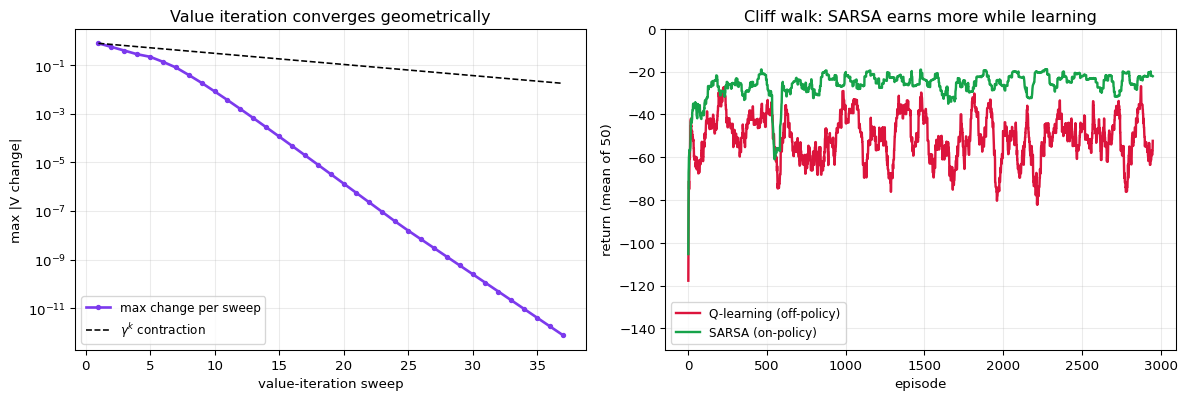

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.plot(np.arange(1, len(history)+1), history, lw=2, marker='o', ms=3,
        color='#7c3aed', label='max change per sweep')
ax.plot(np.arange(1, len(history)+1),
        history[0]*np.power(GAMMA, np.arange(len(history))), 'k--', lw=1.2,
        label=fr'$\gamma^k$ contraction')
ax.set_yscale('log'); ax.set_xlabel('value-iteration sweep')
ax.set_ylabel('max |V change|')
ax.set_title('Value iteration converges geometrically')
ax.legend(fontsize=9); ax.grid(alpha=.25)

ax = axes[1]
w = 50
smooth = lambda x: np.convolve(x, np.ones(w)/w, mode='valid')
ax.plot(smooth(ret_q), lw=1.8, label='Q-learning (off-policy)', color='crimson')
ax.plot(smooth(ret_s), lw=1.8, label='SARSA (on-policy)', color='#16a34a')
ax.set_ylim(-150, 0)
ax.set_xlabel('episode'); ax.set_ylabel(f'return (mean of {w})')
ax.set_title('Cliff walk: SARSA earns more while learning')
ax.legend(fontsize=9); ax.grid(alpha=.25)

plt.tight_layout(); plt.show()

## 7. What to take away

**RL is different because the policy chooses the data.** There is no fixed
training set. Improving the policy changes the distribution you learn from, which
is why nothing from [[cross-validation]] transfers directly.

**The discount is a modelling choice, not a technicality.** It sets an effective
horizon of about $1/(1-\gamma)$ steps and can change which policy is optimal.

**Bellman is one idea stated twice.** The value of a state is the immediate
reward plus the discounted value of the next. With an average over actions it
evaluates a policy; with a maximum it finds the best one. Both converge
geometrically at rate $\gamma$.

**TD learning removes the need for a model** by replacing an expectation with one
sample, and bootstraps a guess from a guess. That it converges at all is the
field's central result.

**Off-policy learns the better policy; on-policy earns the better return while
learning.** The cliff makes this concrete: Q-learning finds the optimal edge path
and keeps falling off it during training; SARSA keeps clearance and scores
better throughout.

**Policy gradients are what scale to language models**, and REINFORCE with a
baseline is the whole idea. Any action-independent baseline keeps the estimator
unbiased while cutting variance — and GRPO's group mean is exactly that baseline.

### Verified in this notebook

- Discounted returns computed term by term and matched against the closed form
- Iterative policy evaluation matched to the exact linear solve $(I - \gamma P)V = r$ to $10^{-6}$ across all states
- Value iteration's observed contraction ratio measured and confirmed to satisfy the $\le \gamma$ bound (it converges faster, as it should — $\gamma$ is the worst case over all MDPs)
- $V^*(s) = \max_a Q^*(s,a)$ checked at a state, with all four action values shown
- Q-learning from sampled experience alone reconstructing $V^*$ to within 0.026 and recovering the optimal action in **all nine** states, with no access to the transition model
- The two conditions that decide whether it converges at all, each shown breaking it: poor state coverage from a fixed start (6/9 actions correct) and a constant step size that leaves a permanent noise floor (7/9). Exploring starts plus a decaying $lpha$ gives 9/9
- SARSA and Q-learning learning genuinely different routes on the cliff, with SARSA's higher training return quantified
- The score-function gradient matched to a finite-difference gradient
- Four baselines shown to be unbiased ($\mathbb{E}[\nabla \log \pi] = 0$ verified directly) with substantially different variances

### Where this connects

[[rlhf-grpo-constitutional-ai]] is this machinery applied to language models —
GRPO is REINFORCE with a group-mean baseline and a trust region.
[[self-improving-llms]] is what happens when the reward comes from the model
itself. [[optimisers-sgd-to-adam]] is the update rule underneath the policy
gradient.